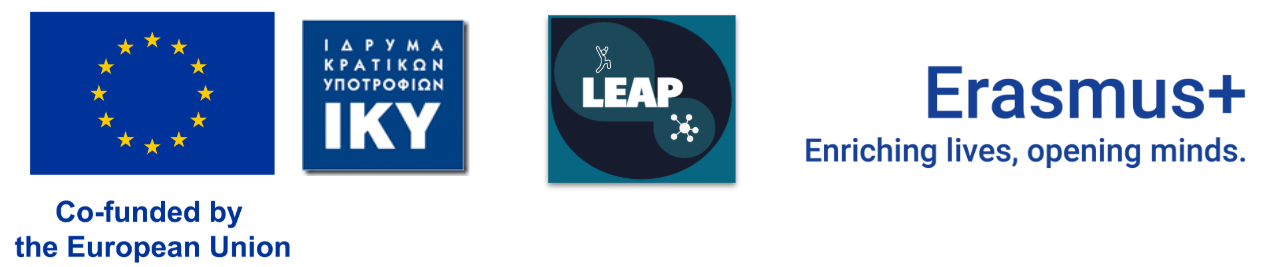

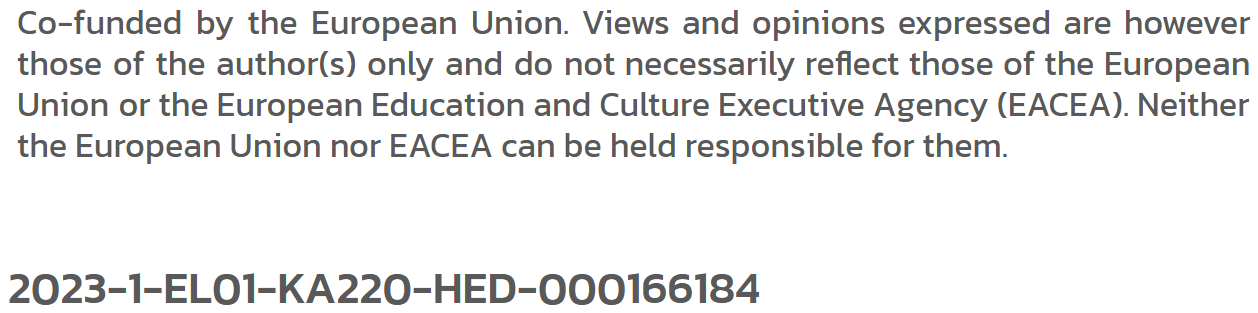

# Final Project, Option 3: How much structure can you find without the labels?

An agricultural co-op receives unlabelled deliveries of mixed wheat grain and wants to know how many distinct varieties are present, and how cleanly they separate, before committing to any sorting process. In this project you recover that structure using clustering alone.

In this project you take a data set with a known grouping, hide that grouping from yourself, and see how much of it you can recover using clustering alone. The labels are kept aside until the very end, where they serve only as an answer key.

**Central question:** how much of the real class structure can you recover without ever using the labels?

The data set is Seeds: 210 wheat kernels described by seven geometric measurements such as area, perimeter, and kernel length. You are given the measurements to work with, and the variety labels are set aside for the final check.

This project draws on Module 4. There we scaled features, reduced them with PCA, clustered with K-Means, chose the number of clusters using the elbow and silhouette methods, and validated the result against a known label with a cross-tabulation. Here you carry out that whole process yourself and judge how faithfully the clusters match the real varieties.

**How this notebook is organised.** The cells in Part A are already written for you. They handle the import, the download, and the scaling. From Part B onward, the cells are yours to complete. Each one carries comments describing what to do, along with a few hints, but not the finished code. Work through them in order, and resist looking at the varieties until Part D.

## Part A. Setup and data

We start with the imports. This cell loads everything the notebook needs, so we run it once at the top.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Plot settings used throughout the notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.titleweight": "bold",
    "font.size": 10,
    "axes.axisbelow": True,
})
NEUTRAL = "#5b6770"                                  # single colour for unlabelled plots
GROUP_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a"]   # three distinct, colour-blind safe hues
VARIETY_NAMES = {1: "Kama", 2: "Rosa", 3: "Canadian"}

os.makedirs("figures", exist_ok=True)               # figures are also saved for the README

### Loading the data

We download the Seeds data set. The seven measurements go into `X`, and the true varieties go into `y_true`. We put the varieties aside now and do not touch them until Part D, so that the clustering is done with no knowledge of the answer.

*Note:* the data are fetched from OpenML. If OpenML cannot be reached, the cell reads the identical copy of the UCI Seeds data stored in `data/seeds.csv` in this repository, so the notebook still runs from top to bottom.

In [2]:
# The Seeds data set: 210 kernels described by seven geometric measurements.
# It is small and fully numeric,
# which suits clustering well.
feature_names = ["area", "perimeter", "compactness", "kernel_length",
                 "kernel_width", "asymmetry", "groove_length"]

try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # keep the output clean if the download is retried
        seeds = fetch_openml(name="seeds", version=1, as_frame=True)
    X = seeds.data.copy()
    y_true = seeds.target.to_numpy().astype(int)
    print("Source: OpenML")
except Exception as err:
    # Offline fallback: same 210 rows from the UCI repository, stored with the project
    local = pd.read_csv("data/seeds.csv")
    X = local[feature_names].copy()
    y_true = local["variety"].to_numpy().astype(int)
    print("Source: data/seeds.csv (OpenML not reachable:", type(err).__name__ + ")")

X.columns = feature_names          # give the seven measurements readable names

# The true varieties. We set these aside now and do NOT use them until Part D,
# where they serve only as an external check on the clustering.

print("Rows and features:", X.shape)
X.head()

Source: OpenML
Rows and features: (210, 7)


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


### Scaling the features

Clustering relies on distances between points, so a feature measured on a larger scale would count for more than the others. We put every feature on the same footing with `StandardScaler`, as in Module 4.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled feature matrix:", X_scaled.shape)

Scaled feature matrix: (210, 7)


## Part B. Explore, without labels

From here on, the cells are yours to complete.

First, look at the shape of the data. Seven measurements are too many to plot at once, so reduce them to two with PCA and draw a scatter. This is the same reduction you used in Module 4.

Explained variance ratio: [0.719 0.171]
Variance captured by the two components: 89.0%


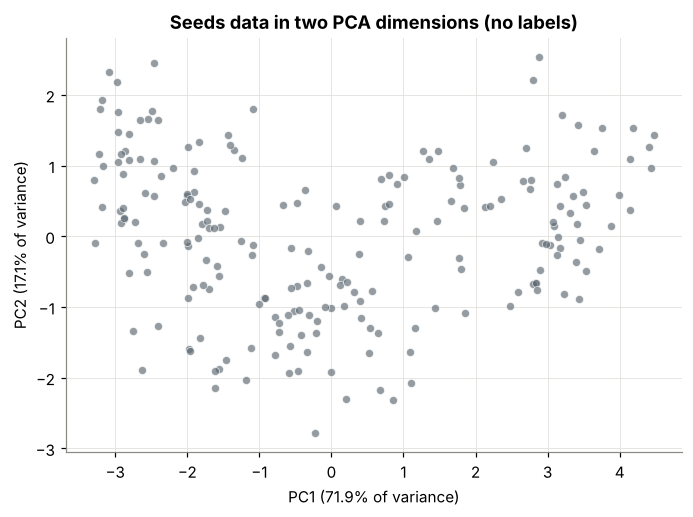

,PC1,PC2
area,0.44,0.03
perimeter,0.44,0.08
compactness,0.28,-0.53
kernel_length,0.42,0.21
kernel_width,0.43,-0.12
asymmetry,-0.12,0.72
groove_length,0.39,0.38


In [4]:
# Reduce the seven features to two so the data can be drawn on a flat plot.
#   - use PCA(n_components=2) and fit_transform on X_scaled, keeping the result as X2
#   - draw a scatter of X2 using a SINGLE colour: at this stage we study the shape
#     of the data without using any labels
#   - print pca.explained_variance_ratio_ to see how much of the variation the
#     two components capture

pca = PCA(n_components=2)
X2 = pca.fit_transform(X_scaled)

evr = pca.explained_variance_ratio_
print("Explained variance ratio:", np.round(evr, 3))
print(f"Variance captured by the two components: {evr.sum():.1%}")

fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.scatter(X2[:, 0], X2[:, 1], s=28, color=NEUTRAL, alpha=0.65,
           edgecolor="white", linewidth=0.6)
ax.set_xlabel(f"PC1 ({evr[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({evr[1]:.1%} of variance)")
ax.set_title("Seeds data in two PCA dimensions (no labels)")
fig.tight_layout()
fig.savefig("figures/01_pca_unlabelled.png", bbox_inches="tight")
plt.show()

# Which measurements drive each component?
loadings = pd.DataFrame(pca.components_.T, index=feature_names, columns=["PC1", "PC2"])
loadings.round(2)

### What do you see?

**Write one or two sentences here** describing the scatter. How many groups seem to be present? Do any of them run into one another?

The two principal components capture about 89% of the variance (PC1 72%, PC2 17%), so the scatter is a fair summary of the seven measurements. PC1 loads almost equally on area, perimeter, length, width and groove length, so it mainly measures kernel size, while PC2 is driven by asymmetry and, with the opposite sign, compactness. The points form a curved band rather than separate islands. There is a dense group of small kernels on the left, a looser group of large kernels on the right and a third concentration around the centre, which suggests two or three groups. The left and centre groups run into each other without a clear gap, and the centre group also touches the right group near PC1 = 1, so any boundary between them will be uncertain.

## Part C. Cluster and choose the number of groups

Now decide how many clusters the data supports, using the two methods from Module 4. The elbow method looks at inertia, the total spread of points around their cluster centres, and finds where adding another cluster stops helping much. The silhouette score measures how well separated the clusters are, where higher is better.

 k  inertia  silhouette
 2    659.2       0.466
 3    430.7       0.401
 4    371.3       0.328
 5    326.5       0.285
 6    289.8       0.280
 7    263.0       0.271


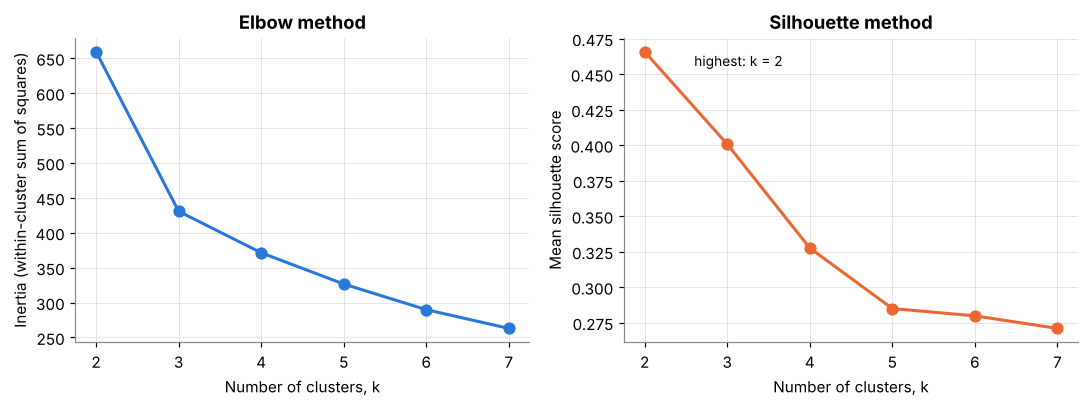

In [5]:
# Work out a sensible number of clusters.
# For each k from 2 to 7:
#   - fit KMeans(n_clusters=k, n_init=10, random_state=42) on X_scaled
#   - record the inertia (km.inertia_) for the elbow method
#   - record the silhouette score, silhouette_score(X_scaled, km.labels_)
# Then plot inertia against k, and silhouette against k, as two small charts.
# For the elbow, look for where the inertia stops dropping sharply.
# For the silhouette, look for the highest value.

k_values = range(2, 8)
inertias, silhouettes = [], []
for k in k_values:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertias.append(km_k.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km_k.labels_))

diagnostics = pd.DataFrame({"k": list(k_values),
                            "inertia": np.round(inertias, 1),
                            "silhouette": np.round(silhouettes, 3)})
print(diagnostics.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(list(k_values), inertias, marker="o", markersize=7, linewidth=2, color=GROUP_COLOURS[0])
ax1.set_xlabel("Number of clusters, k")
ax1.set_ylabel("Inertia (within-cluster sum of squares)")
ax1.set_title("Elbow method")

ax2.plot(list(k_values), silhouettes, marker="o", markersize=7, linewidth=2, color=GROUP_COLOURS[1])
best_k = list(k_values)[int(np.argmax(silhouettes))]
ax2.annotate(f"highest: k = {best_k}", xy=(best_k, max(silhouettes)),
             xytext=(best_k + 0.6, max(silhouettes) - 0.01), fontsize=9)
ax2.set_xlabel("Number of clusters, k")
ax2.set_ylabel("Mean silhouette score")
ax2.set_title("Silhouette method")
for ax in (ax1, ax2):
    ax.set_xticks(list(k_values))
fig.tight_layout()
fig.savefig("figures/02_elbow_silhouette.png", bbox_inches="tight")
plt.show()

### How many clusters?

The elbow and the silhouette will not always point to the same value. That disagreement is part of the exercise. **Write one or two sentences here** stating the value of k you will use and your reason, based on the two charts above.

I use k = 3. The silhouette score is highest at k = 2 (0.47) and falls to 0.40 at k = 3, but the elbow chart shows the largest drop in inertia between k = 2 and k = 3 (from 659 to 431), after which each extra cluster gives only a small gain. The silhouette favours k = 2 because the small and medium kernels are close together and merging them gives a cleaner split, not because only two groups exist. Since three concentrations were visible in the PCA scatter and the inertia curve bends clearly at k = 3, three clusters is the better-supported choice; the lower silhouette value is a warning that the separation between two of them is weak.

### Fit K-Means

Fit K-Means at the number of clusters you decided on, and keep the cluster assignment for each kernel.

In [6]:
# Fit K-Means at your chosen number of clusters.
#   - set k to the value you argued for above
#   - fit KMeans(n_clusters=k, n_init=10, random_state=42) on X_scaled
#   - keep the cluster assignments as `labels`

k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels = km.fit_predict(X_scaled)

print("Clusters:", k)
print("Kernels per cluster:", np.bincount(labels))
print(f"Silhouette at k = {k}: {silhouette_score(X_scaled, labels):.3f}")

Clusters: 3
Kernels per cluster: [72 67 71]
Silhouette at k = 3: 0.401


## Part D. Judge against the labels

We now bring in the true varieties for the first time, only as an external check. The clustering itself is finished; nothing below changes it. We simply ask how well the groups you found line up with the real varieties, exactly as we validated the clusters in Module 4.

Varieties present: [1 2 3]
Variety codes: {1: 'Kama', 2: 'Rosa', 3: 'Canadian'}
true variety   1   2   3
cluster                 
0              6   0  66
1              2  65   0
2             62   5   4


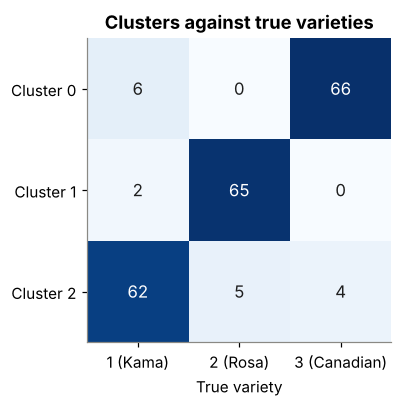

In [7]:
# Reveal the varieties only now, after the clustering is complete.
print("Varieties present:", np.unique(y_true))
print("Variety codes:", VARIETY_NAMES)

# Cross-tabulate the cluster labels against the true varieties.
# Use pd.crosstab(labels, y_true). Each row is a cluster, each column a variety.
# A clean clustering has most of each row concentrated in a single column.

ct = pd.crosstab(labels, y_true, rownames=["cluster"], colnames=["true variety"])
print(ct)

# Same table as a heat map, so the off-diagonal counts are easy to spot
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.imshow(ct.values, cmap="Blues", vmin=0)
ax.grid(False)
ax.set_xticks(range(ct.shape[1]), [f"{v} ({VARIETY_NAMES[v]})" for v in ct.columns])
ax.set_yticks(range(ct.shape[0]), [f"Cluster {c}" for c in ct.index])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        val = ct.values[i, j]
        ax.text(j, i, val, ha="center", va="center",
                color="white" if val > ct.values.max() / 2 else "#1f1f1f", fontsize=11)
ax.set_xlabel("True variety")
ax.set_title("Clusters against true varieties")
fig.tight_layout()
fig.savefig("figures/03_crosstab.png", bbox_inches="tight")
plt.show()

### Measuring the agreement

Turn the table into a single number with a purity score. For each cluster, take the count of its most common variety; add those counts across all clusters; then divide by the total number of kernels. A value near 1 means each cluster is almost entirely one variety.

Purity tends to increase when more clusters are created, so interpret it together with your chosen value of `k` and the cross-tabulation rather than using it on its own.

In [8]:
# Compute the purity score from `ct`.
#   - for each cluster (each row), take the largest count: ct.max(axis=1)
#   - add these across clusters, then divide by the total, ct.values.sum()

purity = ct.max(axis=1).sum() / ct.values.sum()
print(f"Purity: {purity:.3f}  ({ct.max(axis=1).sum()} of {ct.values.sum()} kernels "
      "sit in a cluster whose majority variety matches their own)")

# Per-cluster view: majority variety and share of the cluster it makes up
per_cluster = pd.DataFrame({
    "size": ct.sum(axis=1),
    "majority variety": ct.idxmax(axis=1).map(VARIETY_NAMES),
    "share of majority": (ct.max(axis=1) / ct.sum(axis=1)).round(3),
})
per_cluster

Purity: 0.919  (193 of 210 kernels sit in a cluster whose majority variety matches their own)


,size,majority variety,share of majority
cluster,,,
0,72,Canadian,0.917
1,67,Rosa,0.970
2,71,Kama,0.873


### Back to the picture

Connect the numbers to the shape you saw earlier. Redraw the PCA scatter, but this time colour each point by its true variety. Interpret this picture cautiously: K-Means used all seven scaled features, while the plot shows only two PCA dimensions. Points that overlap here may still be separated by information in the other dimensions.

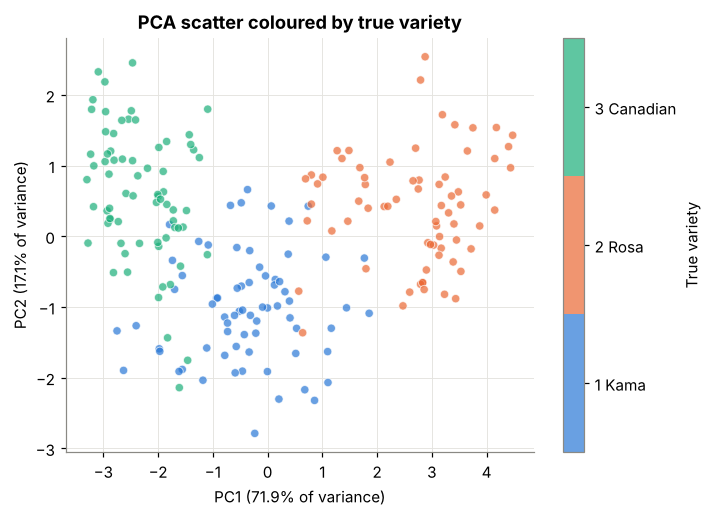

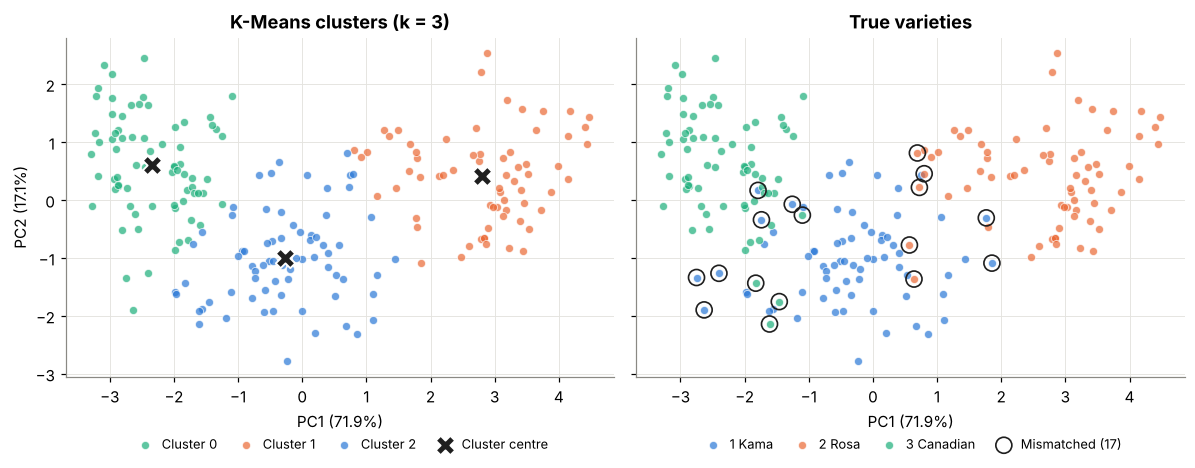

In [9]:
# Redraw the scatter of X2 (from Part B), now coloured by the true variety y_true.
# In plt.scatter(...), use c=y_true, alpha=0.7 and a three-colour map.
# Add axis labels and a colour bar labelled "True variety".
#
# A three-colour map is used instead of the continuous "viridis" scale,
# because the varieties are categories rather than an ordered quantity.

variety_cmap = ListedColormap(GROUP_COLOURS)

fig, ax = plt.subplots(figsize=(6.6, 4.8))
sc = ax.scatter(X2[:, 0], X2[:, 1], c=y_true, cmap=variety_cmap, alpha=0.7,
                s=30, edgecolor="white", linewidth=0.6)
cbar = fig.colorbar(sc, ax=ax, ticks=[1 + 2/6, 2, 3 - 2/6])
cbar.ax.set_yticklabels([f"{v} {VARIETY_NAMES[v]}" for v in (1, 2, 3)])
cbar.set_label("True variety")
ax.set_xlabel(f"PC1 ({evr[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({evr[1]:.1%} of variance)")
ax.set_title("PCA scatter coloured by true variety")
fig.tight_layout()
fig.savefig("figures/04_pca_true_variety.png", bbox_inches="tight")
plt.show()

# Side by side: what K-Means found next to the real varieties.
# Each cluster takes the colour of the variety that dominates it, so the two
# panels can be compared directly. Kernels whose cluster's majority variety
# differs from their own are circled.
majority = ct.idxmax(axis=1)
cluster_colour = {c: GROUP_COLOURS[majority[c] - 1] for c in range(k)}
mismatch = majority.loc[labels].to_numpy() != y_true
centres_2d = pca.transform(km.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for c in range(k):
    m = labels == c
    axes[0].scatter(X2[m, 0], X2[m, 1], s=28, alpha=0.7, color=cluster_colour[c],
                    edgecolor="white", linewidth=0.6, label=f"Cluster {c}")
axes[0].scatter(centres_2d[:, 0], centres_2d[:, 1], marker="X", s=160,
                color="#1f1f1f", edgecolor="white", linewidth=1.2, label="Cluster centre")
axes[0].set_title("K-Means clusters (k = 3)")

for v in (1, 2, 3):
    m = y_true == v
    axes[1].scatter(X2[m, 0], X2[m, 1], s=28, alpha=0.7, color=GROUP_COLOURS[v - 1],
                    edgecolor="white", linewidth=0.6, label=f"{v} {VARIETY_NAMES[v]}")
axes[1].scatter(X2[mismatch, 0], X2[mismatch, 1], s=110, facecolor="none",
                edgecolor="#1f1f1f", linewidth=1.1, label=f"Mismatched ({mismatch.sum()})")
axes[1].set_title("True varieties")

for ax in axes:
    ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
    ax.legend(frameon=False, fontsize=8.5, loc="upper center",
              bbox_to_anchor=(0.5, -0.14), ncol=4, handletextpad=0.3, columnspacing=1.2)
axes[0].set_ylabel(f"PC2 ({evr[1]:.1%})")
fig.tight_layout()
fig.savefig("figures/05_clusters_vs_varieties.png", bbox_inches="tight")
plt.show()

### What each cluster captured

Finally, see what each cluster actually represents. The cluster centres are stored in scaled units, so turn them back into the original measurements with `scaler.inverse_transform`, and read across each row to picture the typical kernel in that group.

         kernels    area  perimeter  compactness  kernel_length  kernel_width  asymmetry  groove_length majority variety
cluster                                                                                                                 
0             72  11.857     13.248        0.848          5.232         2.850      4.742          5.102         Canadian
1             67  18.495     16.203        0.884          6.176         3.698      3.632          6.042             Rosa
2             71  14.438     14.338        0.882          5.515         3.259      2.707          5.121             Kama


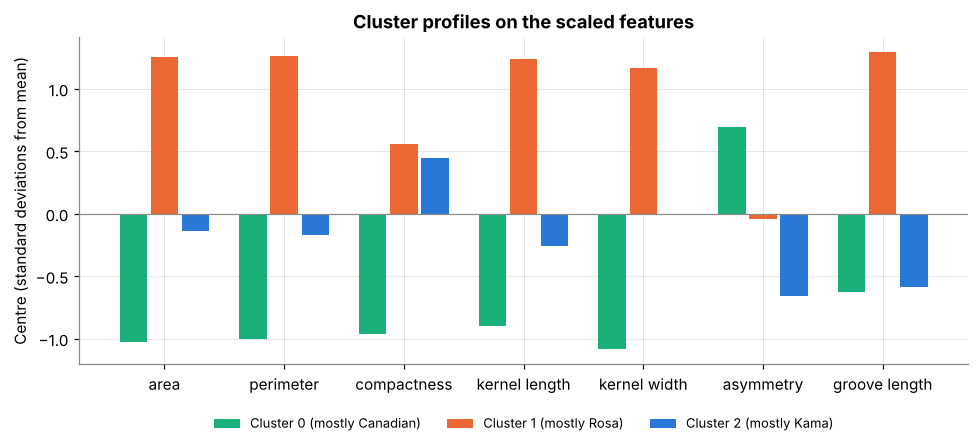

In [10]:
# Describe each cluster by its centre, in the original measurement units.
#   - the centres in scaled space are km.cluster_centers_ (from your fitted model)
#   - convert them back with scaler.inverse_transform(...)
#   - put the result in a DataFrame with columns=feature_names so it reads clearly

profiles = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_),
                        columns=feature_names).round(3)
profiles.index.name = "cluster"
profiles.insert(0, "kernels", np.bincount(labels))
profiles["majority variety"] = majority.map(VARIETY_NAMES)
print(profiles.to_string())

# Each cluster centre relative to the overall mean, in standard deviations
fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.26
pos = np.arange(len(feature_names))
for c in range(k):
    ax.bar(pos + (c - 1) * width, km.cluster_centers_[c], width=width - 0.03,
           color=cluster_colour[c], label=f"Cluster {c} (mostly {VARIETY_NAMES[majority[c]]})")
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.set_xticks(pos, [f.replace("_", " ") for f in feature_names])
ax.set_ylabel("Centre (standard deviations from mean)")
ax.set_title("Cluster profiles on the scaled features")
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
fig.tight_layout()
fig.savefig("figures/06_cluster_profiles.png", bbox_inches="tight")
plt.show()

### Ethical considerations

Clustering will always return groups, whether or not they reflect anything real. Treating those groups as fixed, meaningful categories, and acting on them, can do harm if the data does not truly support them.

**Write two or three sentences here** on the risks of over-reading this result. Consider what could go wrong if the co-op treated your clusters as definite varieties, and how the purity score and your choice of k should temper the confidence of any claim you make.

K-Means returns exactly as many groups as it is asked for, so the three clusters found here are partly a product of the choice of k and not proof that three varieties exist. A purity of 0.92 also means that 17 of the 210 kernels (about 8%) were placed in a cluster dominated by another variety, most of them (10) on the border between the small Canadian and medium Kama kernels. If the co-op treated the clusters as definite varieties, for example to set prices, sort deliveries or certify seed, these borderline kernels would be mislabelled systematically and the error would not be visible without a labelled check. The cluster assignments should therefore be presented as a working hypothesis, with the silhouette values, the disagreement between the two diagnostics and the purity score reported alongside them, and confirmed on a labelled sample before any decision depends on them.

## Wrapping up

Bring your findings together. **Write a short paragraph** that answers the central question directly:

- How many groups did the diagnostics support, and how did you decide when the elbow and the silhouette disagreed?
- From the cross-tabulation and the purity score, how much of the real variety structure did the clustering recover?
- Which variety was separated most cleanly, and which two were the hardest to tell apart? Does the coloured scatter support this interpretation?
- Why must you be cautious when judging a seven-dimensional clustering from a two-dimensional PCA plot?

**What to hand in:** this completed notebook, with the diagnostic charts, the cross-tabulation, the purity score, both scatter plots, and the cluster profiles visible in the output, and your written answers in the three markdown cells (Part B, Part C, and this one).

The diagnostics supported two or three groups. The silhouette score peaked at k = 2, while the elbow in the inertia curve was at k = 3; I chose k = 3 because the elbow was clear, the PCA scatter showed three concentrations and the silhouette at k = 3 (0.40) was still reasonable. Clustering without labels recovered most of the real structure: the cross-tabulation is strongly diagonal and the purity is 0.919, meaning 193 of 210 kernels lie in a cluster whose majority variety is their own. Rosa was separated most cleanly (65 of 70 kernels in one cluster, and that cluster is 97% Rosa), which matches its position as the group of large kernels at the right of the scatter. Kama and Canadian were the hardest pair to tell apart, with 10 kernels crossing between their clusters, and Kama, which lies between the other two varieties in size, also lost 2 kernels to the Rosa cluster and received 5 Rosa kernels. The coloured scatter supports this reading, since the Kama points occupy the middle of the band and overlap both neighbours, while the cluster profiles show that size explains most of the split and that asymmetry and compactness help to separate Canadian from Kama. Caution is still needed when judging the result from the PCA plot. K-Means worked in all seven scaled dimensions, and the two components leave out about 11% of the variance, so points that overlap in the plot may be separated in the full space and points that look well placed may not be. The plot is a projection that helps interpretation, but it is not the space in which the clusters were formed.